In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

In [ ]:
# Load TPM expression matrix

tpm = pd.read_csv(
    "tpm.csv",
    index_col=0
)

print("Dataset dimensions:", tpm.shape)
print(tpm.head())

Dataset dimensions: (19472, 126)
           C1    C2    C3    C4    C5    C6    C7    C8    C9   C10  ...  \
#symbol                                                              ...   
A1BG     0.49  0.29  0.26  0.45  0.17  0.21  0.49  0.12  0.51  0.10  ...   
A1CF     0.00  0.00  0.00  0.01  0.00  0.00  0.01  0.00  0.01  0.00  ...   
A2M      0.21  0.14  0.03  0.09  0.00  0.08  0.23  0.08  0.88  0.13  ...   
A2ML1    0.04  0.00  0.02  0.07  0.05  0.04  0.03  0.01  0.02  0.01  ...   
A3GALT2  0.07  0.00  0.00  0.00  0.07  0.00  0.07  0.00  0.79  0.15  ...   

         NC17  NC18  NC19  NC20  NC21  NC22  NC23  NC24  NC25  NC26  
#symbol                                                              
A1BG     0.37  0.33  0.25  0.20  0.40  0.30  0.70  0.75  2.80  0.22  
A1CF     0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  
A2M      0.07  0.06  0.11  0.01  0.04  0.02  0.02  0.27  0.04  0.28  
A2ML1    0.01  0.00  0.00  0.02  0.02  0.02  0.01  0.00  0.00  0.00  
A3GALT2  0.18 

In [ ]:
# Transpose: samples as rows, genes as columns

X = tpm.T.astype(float)

# Identify COVID and non-COVID samples
labels = pd.Series(
    [
        "COVID Positive" if sample.startswith("C")
        and not sample.startswith("NC")
        else "COVID Negative"
        for sample in X.index
    ],
    index=X.index
)

print("Expression matrix:", X.shape)

print("\nSample distribution:")
print(labels.value_counts())

Expression matrix: (126, 19472)

Sample distribution:
COVID Positive    100
COVID Negative     26
Name: count, dtype: int64


In [ ]:
# Log2 transformation of TPM values
X_log = np.log2(X + 1)

print("Log-transformed dimensions:", X_log.shape)
print(X_log.head())

Log-transformed dimensions: (126, 19472)
#symbol      A1BG      A1CF       A2M     A2ML1   A3GALT2  A4GALT     A4GNT  \
C1       0.575312  0.000000  0.275007  0.056584  0.097611     0.0  0.042644   
C2       0.367371  0.000000  0.189034  0.000000  0.000000     0.0  0.070389   
C3       0.333424  0.000000  0.042644  0.028569  0.000000     0.0  0.097611   
C4       0.536053  0.014355  0.124328  0.097611  0.000000     0.0  0.000000   
C5       0.226509  0.000000  0.000000  0.070389  0.097611     0.0  0.000000   

#symbol      AAAS      AACS  AADAC  ...    ZWILCH     ZWINT      ZXDA  \
C1       4.316146  2.341986    0.0  ...  1.941106  2.384050  0.963474   
C2       4.298658  2.000000    0.0  ...  2.185867  3.716991  0.678072   
C3       3.892391  1.500802    0.0  ...  1.226509  1.922198  0.238787   
C4       4.530445  2.384050    0.0  ...  2.235727  2.780310  1.263034   
C5       3.240314  1.117695    0.0  ...  1.286881  2.448901  0.356144   

#symbol      ZXDB      ZXDC    ZYG11A    ZYG1

In [ ]:
# Count samples in which each gene has TPM > 1
expressed_samples = (X > 1).sum(axis=0)

# At least 10% of samples must express the gene
min_samples = int(np.ceil(0.10 * X.shape[0]))

selected_genes = expressed_samples >= min_samples

# Keep selected genes
X_filtered = X_log.loc[:, selected_genes]

print("Genes before filtering:", X_log.shape[1])
print("Genes after filtering:", X_filtered.shape[1])
print("Filtered data dimensions:", X_filtered.shape)

Genes before filtering: 19472
Genes after filtering: 11888
Filtered data dimensions: (126, 11888)


In [ ]:
from sklearn.decomposition import PCA
import numpy as np

# Safely delete any globally shadowed 'sum' variable to restore the built-in function
if 'sum' in globals() and not callable(globals()['sum']):
    del globals()['sum']

# Reduce the data to 100 principal components
pca = PCA(n_components=100)

X_pca = pca.fit_transform(X_filtered)

print("PCA output dimensions:", X_pca.shape)

# Calculate cumulative variance
variance_pct = pca.explained_variance_ratio_ * 100
cumulative_variance = np.cumsum(variance_pct)

# Find the number of components needed for 80% variance
components_80 = np.argmax(cumulative_variance >= 80.0) + 1

print(f"Number of components to capture 80% variance: {components_80}\n")

# Print individual variance values up to PC37
print("Individual Variance Explained:")
for idx in range(components_80):
    print(f"PC{idx+1}: {variance_pct[idx]:.4f}% (Cumulative: {cumulative_variance[idx]:.2f}%)")

print(f"\nTotal variance explained by these {components_80} components: {cumulative_variance[components_80-1]:.2f}%")
print("Total variance explained by all 100 components:", sum(pca.explained_variance_ratio_) * 100, "%")

PCA output dimensions: (126, 100)
Number of components to capture 80% variance: 9

Individual Variance Explained:
PC1: 37.2278% (Cumulative: 37.23%)
PC2: 23.3984% (Cumulative: 60.63%)
PC3: 4.7027% (Cumulative: 65.33%)
PC4: 4.3340% (Cumulative: 69.66%)
PC5: 3.6048% (Cumulative: 73.27%)
PC6: 2.1766% (Cumulative: 75.44%)
PC7: 1.8552% (Cumulative: 77.30%)
PC8: 1.4402% (Cumulative: 78.74%)
PC9: 1.2732% (Cumulative: 80.01%)

Total variance explained by these 9 components: 80.01%
Total variance explained by all 100 components: 98.6617251348575 %


In [ ]:
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Group": labels.to_numpy()
}, index=X.index)

print(pca_df.head())

          PC1        PC2           Group
C1  58.231608 -14.930228  COVID Positive
C2  42.534852 -14.431470  COVID Positive
C3  -3.344556  23.935775  COVID Positive
C4  68.303682 -32.569453  COVID Positive
C5  12.701818  44.769023  COVID Positive


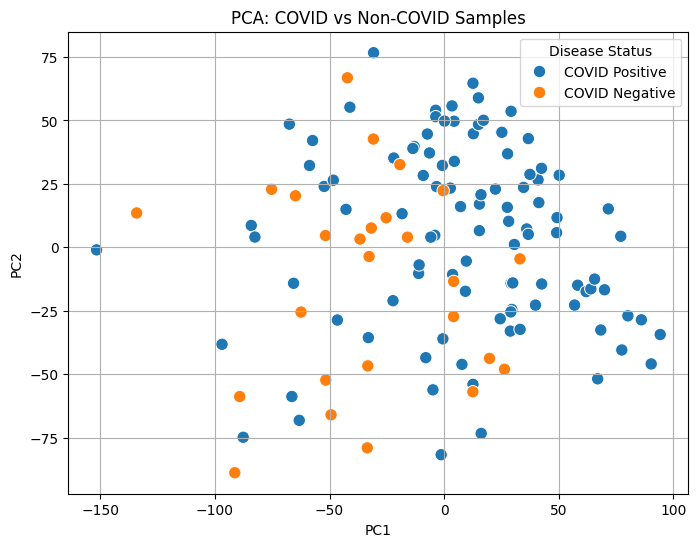

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Group",
    s=80
)

plt.title("PCA: COVID vs Non-COVID Samples")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Disease Status")
plt.grid(True)
plt.show()

In [ ]:
!pip install umap-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import umap.umap_ as umap

In [ ]:
# Initialize UMAP
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='euclidean',
    random_state=42
)

# Perform dimensionality reduction
X_umap = reducer.fit_transform(X_filtered)

print("UMAP output dimensions:", X_umap.shape)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP output dimensions: (126, 2)


In [ ]:
umap_df = pd.DataFrame({
    "UMAP1": X_umap[:, 0],
    "UMAP2": X_umap[:, 1],
    "Group": labels
}, index=X.index)

print(umap_df.head())

       UMAP1      UMAP2           Group
C1  1.702000  13.350309  COVID Positive
C2  1.974899  12.468405  COVID Positive
C3 -1.731330  10.482745  COVID Positive
C4  2.647334  13.224638  COVID Positive
C5 -0.991032  11.950569  COVID Positive


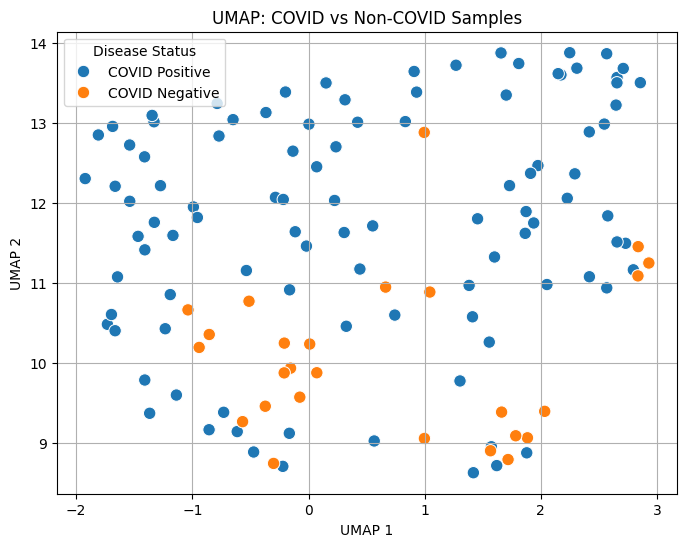

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="Group",
    s=80
)

plt.title("UMAP: COVID vs Non-COVID Samples")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="Disease Status")
plt.grid(True)
plt.show()

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X_filtered.columns,
    columns=[f"PC{i+1}" for i in range(100)]
)

print("Top genes contributing to PC1:")
print(loadings["PC1"].abs().nlargest(15))

print("Top genes contributing to PC2:")
print(loadings["PC2"].abs().nlargest(15))

Top genes contributing to PC1:
#symbol
JCHAIN    0.029500
SNURF     0.028914
OAS3      0.027140
TUBB1     0.026360
HBA2      0.025899
IFI44L    0.025677
LUC7L2    0.024639
XAF1      0.024158
RBL2      0.023836
TXNDC5    0.023732
HBA1      0.023657
ITK       0.023653
ITGA4     0.023531
OAS2      0.023479
IFI27     0.023474
Name: PC1, dtype: float64
Top genes contributing to PC2:
#symbol
OLAH       0.051120
ARG1       0.046304
CD177      0.045350
IL1R2      0.043723
IL18R1     0.040969
LGALS2     0.040764
PFKFB2     0.037419
DAAM2      0.037061
VNN1       0.035551
PTPRCAP    0.035450
GNLY       0.034988
FKBP5      0.034900
MMP8       0.034584
FCER1A     0.033255
TPST1      0.032521
Name: PC2, dtype: float64
